In [1]:
%run -i ./01_cleaning.ipynb

{'Students': (1002, 12), 'Groups': (41, 8), 'Sessions': (1442, 6), 'Records': (34834, 16), 'Payments': (8713, 9)}
Students  (1002, 12)
Groups    (41, 8)
Sessions  (1442, 6)
Records   (34834, 16)
Payments  (8713, 9)
القيم الناقصة في كل جدول (الأعمدة اللي فيها فاضي بس):

Students: {'name': 1, 'phone': 1, 'parent_phone': 1, 'group_id': 1, 'gender': 1, 'grade': 1, 'school_type': 1, 'area': 1, 'join_date': 1, 'status': 1, 'leave_date': 972}

Groups: {'group_name': 1, 'day': 1, 'time': 1, 'grade': 1, 'track': 1, 'monthly_fee': 1, 'start_date': 1}

Sessions: {'group_id': 1, 'date': 1, 'session_number': 1, 'month': 1, 'session_type': 1}

Records: {'student_id': 43, 'session_id': 43, 'date': 43, 'attendance': 43, 'homework': 43, 'exam_score': 2744, 'max_exam_score': 2745, 'percentage': 2744, 'notes': 2721, 'student_session_number': 43, 'group_month': 43, 'group_session': 43, 'student_month': 43, 'student_session': 44, 'attendance_notes': 31883}

Payments: {'student_id': 10, 'month_label': 10, '

In [3]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

from src import rules

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

print({k: len(v) for k, v in clean.items()})

{'Students': 1000, 'Groups': 40, 'Sessions': 1440, 'Records': 34765, 'Payments': 8696}


In [4]:
HW_MAP = {'ممتاز': 5, 'جيد جدا': 4, 'جيد': 3, 'مقبول': 2, 'ضعيف': 1, 'لم يسلم': 0}
num = lambda s: pd.to_numeric(s, errors='coerce')

# --- records + sessions (month, session_number) ---
rec = clean['Records'].dropna(subset=['student_id', 'session_id']).copy()
for c in ['exam_score', 'max_exam_score', 'percentage']:
    rec[c] = num(rec[c])

ses = clean['Sessions'][['session_id', 'session_number', 'month']].copy()
ses['session_number'] = num(ses['session_number'])
ses['month'] = num(ses['month'])

rec = rec.merge(ses, on='session_id', how='left')

# --- row-level helper columns ---
rec['attended'] = rules.attended(rec['attendance']).astype(int)   # present or late
rec['is_late']  = rules.is_late(rec['attendance']).astype(int)
rec['excused']  = (rec['attendance'] == 'excused').astype(int)
rec['hw_score'] = rec['homework'].map(HW_MAP)

rec = rec.sort_values(['student_id', 'session_number']).reset_index(drop=True)

# --- sanity checks ---
print("records:", rec.shape, "| students:", rec['student_id'].nunique())
print("\nattendance values:", rec['attendance'].value_counts(dropna=False).to_dict())
print("\nmissing per column:")
print(rec[['attendance', 'hw_score', 'exam_score', 'percentage', 'month']].isna().sum().to_string())

records: (34765, 22) | students: 1000

attendance values: {'present': 31416, 'absent': 1718, 'excused': 982, 'late': 649}

missing per column:
attendance       0
hw_score        39
exam_score    2700
percentage    2700
month            0


(1000, 4)
       n_sessions  att_rate  excused_rate  late_rate
count    1000.000  1000.000      1000.000   1000.000
mean       34.765     0.920         0.029      0.020
std         4.588     0.106         0.044      0.029
min         8.000     0.333         0.000      0.000
25%        36.000     0.889         0.000      0.000
50%        36.000     0.944         0.000      0.000
75%        36.000     1.000         0.036      0.030
max        39.000     1.000         0.294      0.167


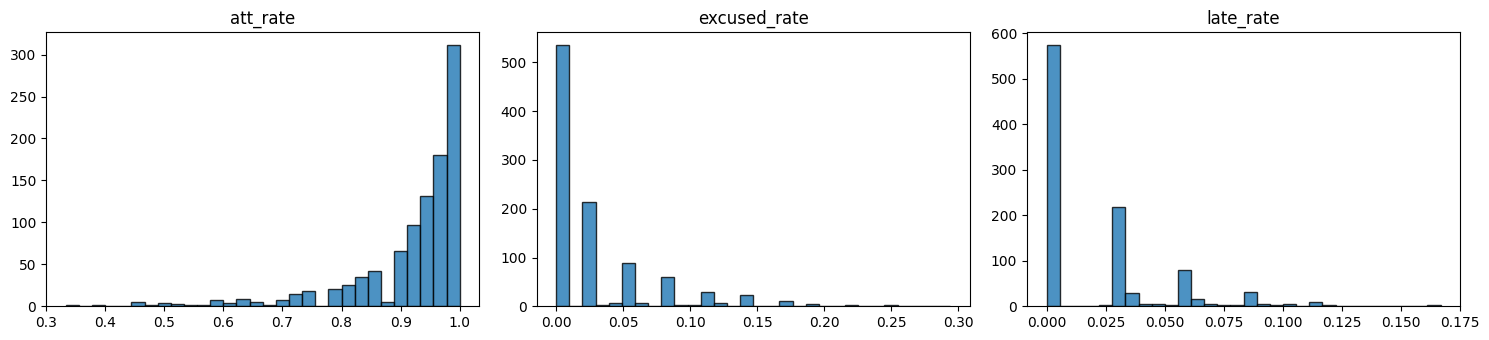

In [5]:
g = rec.groupby('student_id')

feat = pd.DataFrame({
    'n_sessions':   g.size(),
    'att_rate':     g['attended'].mean(),                       # present or late, out of all sessions
    'excused_rate': g['excused'].mean(),                        # excused out of all sessions
    'late_rate':    g['is_late'].sum() / g['attended'].sum(),   # late out of attended sessions only
})

print(feat.shape)
print(feat.describe().round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ['att_rate', 'excused_rate', 'late_rate']):
    ax.hist(feat[c], bins=30, edgecolor='k', alpha=0.8)
    ax.set_title(c)
plt.tight_layout(); plt.show()

(1000, 8)
        avg_pct   std_pct  pct_slope    hw_avg
count  1000.000  1000.000    997.000  1000.000
mean      0.814     0.086      0.004     3.302
std       0.143     0.030      0.014     1.029
min       0.309     0.023     -0.077     0.741
25%       0.785     0.068     -0.001     2.794
50%       0.868     0.083      0.003     3.556
75%       0.908     0.098      0.009     4.083
max       0.991     0.208      0.061     4.882

missing:
pct_slope    3


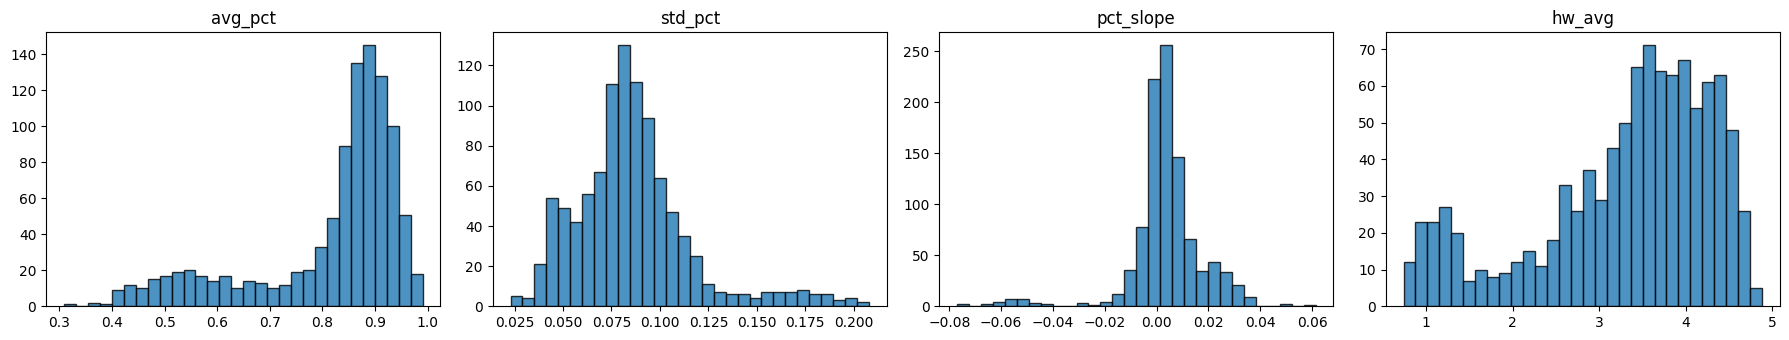

In [6]:
# --- exam performance (only sessions that have a grade) ---
ex = rec.dropna(subset=['percentage'])

def monthly_slope(d):
    """Slope of the monthly mean percentage (change per month). NaN if < 3 months."""
    m = d.groupby('month')['percentage'].mean()
    return np.polyfit(m.index, m.values, 1)[0] if len(m) >= 3 else np.nan

perf = pd.DataFrame({
    'avg_pct': ex.groupby('student_id')['percentage'].mean(),
    'std_pct': ex.groupby('student_id')['percentage'].std(),
    'pct_slope': ex.groupby('student_id').apply(monthly_slope),
})

# --- homework: attended sessions only (absent rows are filled with "لم يسلم" = 0 by the cleaning) ---
att_rows = rec[rec['attended'] == 1]
perf['hw_avg'] = att_rows.groupby('student_id')['hw_score'].mean()

feat = feat.join(perf)

print(feat.shape)
print(feat[['avg_pct', 'std_pct', 'pct_slope', 'hw_avg']].describe().round(3).to_string())
print("\nmissing:"); print(feat.isna().sum()[lambda s: s > 0].to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, c in zip(axes, ['avg_pct', 'std_pct', 'pct_slope', 'hw_avg']):
    ax.hist(feat[c].dropna(), bins=30, edgecolor='k', alpha=0.8)
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [7]:
pay = clean['Payments'].dropna(subset=['student_id']).copy()
pay['due_date']  = pd.to_datetime(pay['due_date'],  errors='coerce')
pay['paid_date'] = pd.to_datetime(pay['paid_date'], errors='coerce')
pay['delay_days'] = (pay['paid_date'] - pay['due_date']).dt.days   # NaN when never paid

gp = pay.groupby('student_id')
pf = pd.DataFrame({
    'n_payments':    gp.size(),
    'unpaid_rate':   gp['status'].apply(lambda s: (s == 'unpaid').mean()),
    'partial_rate':  gp['status'].apply(lambda s: (s == 'partial').mean()),
    'paid_late_rate': gp['status'].apply(lambda s: (s == 'paid_late').mean()),
    'exempt_rate':   gp['status'].apply(lambda s: (s == 'exempt').mean()),
    'avg_delay_days': gp['delay_days'].mean(),    # only over payments that were actually paid
})

feat = feat.join(pf)

print(feat.shape)
print(pf.describe().round(3).to_string())
print("\nstatus counts:", pay['status'].value_counts(dropna=False).to_dict())
print("\nmissing:"); print(feat.isna().sum()[lambda s: s > 0].to_string())
print("\nstudents with exempt_rate > 0:", (feat['exempt_rate'] > 0).sum())

(1000, 14)
       n_payments  unpaid_rate  partial_rate  paid_late_rate  exempt_rate  avg_delay_days
count    1000.000     1000.000      1000.000        1000.000     1000.000         967.000
mean        8.695        0.076         0.040           0.098        0.030           2.067
std         1.111        0.178         0.138           0.206        0.171           4.227
min         2.000        0.000         0.000           0.000        0.000          -3.250
25%         9.000        0.000         0.000           0.000        0.000          -0.750
50%         9.000        0.000         0.000           0.000        0.000           0.125
75%         9.000        0.111         0.000           0.111        0.000           3.667
max         9.000        1.000         0.857           1.000        1.000          19.444

status counts: {'paid': 6592, 'paid_late': 841, 'unpaid': 645, 'partial': 347, 'exempt': 270}

missing:
pct_slope          3
avg_delay_days    33

students with exempt_rate > 0: 

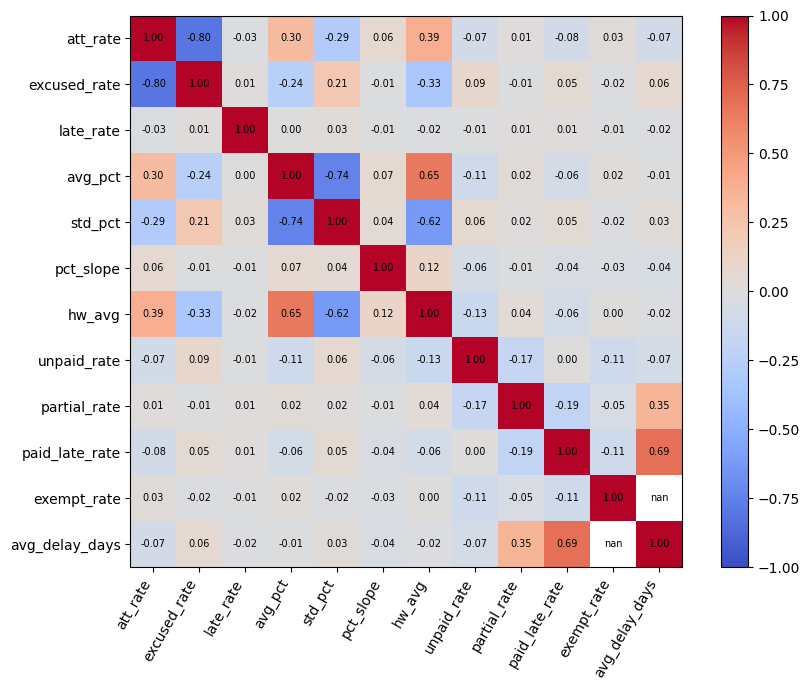

            f1             f2    rho
      att_rate   excused_rate -0.798
       avg_pct        std_pct -0.736
paid_late_rate avg_delay_days  0.685
       avg_pct         hw_avg  0.646
       std_pct         hw_avg -0.618

skewness:
exempt_rate       5.52
partial_rate      3.49
unpaid_rate       2.89
paid_late_rate    2.30
att_rate         -2.18
excused_rate      2.14
late_rate         1.64
avg_delay_days    1.58
pct_slope        -1.52
avg_pct          -1.38
std_pct           1.21
hw_avg           -0.89


In [8]:
cols = ['att_rate', 'excused_rate', 'late_rate', 'avg_pct', 'std_pct', 'pct_slope', 'hw_avg',
        'unpaid_rate', 'partial_rate', 'paid_late_rate', 'exempt_rate', 'avg_delay_days']

corr = feat[cols].corr(method='spearman')   # spearman: robust to the skewed (mostly-zero) columns

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha='right')
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
fig.colorbar(im); plt.tight_layout(); plt.show()

# strongly correlated pairs (|rho| >= 0.6)
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename('rho').reset_index())
pairs.columns = ['f1', 'f2', 'rho']
print(pairs[pairs['rho'].abs() >= 0.6].sort_values('rho', key=abs, ascending=False).round(3).to_string(index=False))

# skewness
print("\nskewness:"); print(feat[cols].skew().round(2).sort_values(key=abs, ascending=False).to_string())

In [9]:
# 3 students have grades in < 3 months, so no slope: look at them, then use 0 (= "no trend")
nan_slope = feat.index[feat['pct_slope'].isna()]
print(feat.loc[nan_slope, ['n_sessions', 'att_rate', 'avg_pct']].round(3).to_string())
feat['pct_slope'] = feat['pct_slope'].fillna(0)

FEATURE_SETS = {
    'core':     ['att_rate', 'late_rate', 'avg_pct', 'pct_slope', 'hw_avg',
                 'unpaid_rate', 'partial_rate', 'paid_late_rate'],
}
FEATURE_SETS['core_std'] = FEATURE_SETS['core'] + ['std_pct']

# kept in `feat` for profiling the clusters later, NOT used for clustering
PROFILE_ONLY = ['exempt_rate', 'avg_delay_days', 'excused_rate', 'n_sessions', 'n_payments']

for name, cols_ in FEATURE_SETS.items():
    print(f"\n{name}: {len(cols_)} features | NaN cells = {int(feat[cols_].isna().sum().sum())}")
    print(cols_)

            n_sessions  att_rate  avg_pct
student_id                               
S0173                8     0.500    0.525
S0332               10     0.600    0.567
S0794                9     0.444    0.768

core: 8 features | NaN cells = 0
['att_rate', 'late_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'unpaid_rate', 'partial_rate', 'paid_late_rate']

core_std: 9 features | NaN cells = 0
['att_rate', 'late_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'unpaid_rate', 'partial_rate', 'paid_late_rate', 'std_pct']


In [10]:
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer

SQRT_COLS = ['late_rate', 'unpaid_rate', 'partial_rate', 'paid_late_rate']
TRANSFORMS = ['none', 'sqrt', 'yeo']          # yeo = Yeo-Johnson
SCALERS    = {'standard': StandardScaler, 'robust': RobustScaler}

def prepare(cols_, how, scaler):
    X = feat[cols_].copy()
    if how == 'sqrt':
        for c in SQRT_COLS:
            if c in X.columns:
                X[c] = np.sqrt(X[c])
    elif how == 'yeo':
        pt = PowerTransformer(method='yeo-johnson', standardize=False)   # scaling is done by the scaler below
        X = pd.DataFrame(pt.fit_transform(X), index=X.index, columns=X.columns)
    sc = SCALERS[scaler]()
    return pd.DataFrame(sc.fit_transform(X), index=X.index, columns=X.columns)

# VARIANTS[(feature_set, "transform+scaler")] -> scaled DataFrame
VARIANTS = {(fs, f"{t}+{s}"): prepare(cols_, t, s)
            for fs, cols_ in FEATURE_SETS.items()
            for t in TRANSFORMS for s in SCALERS}

print(len(VARIANTS), "variants")

# skewness of each feature under each combination (core set)
skew = pd.DataFrame({k[1]: v.skew() for k, v in VARIANTS.items() if k[0] == 'core'})
print(skew.round(2).to_string())

# how far do extreme students stretch each space? (max |value| over all features)
spread = pd.Series({k[1]: v.abs().max().max() for k, v in VARIANTS.items() if k[0] == 'core'})
print("\nmax |value|:"); print(spread.round(1).to_string())

# columns where the IQR is 0 (RobustScaler falls back to scale=1 for them)
iqr = feat[FEATURE_SETS['core']].quantile(.75) - feat[FEATURE_SETS['core']].quantile(.25)
print("\nIQR == 0 columns:", list(iqr[iqr == 0].index))

12 variants
                none+standard  none+robust  sqrt+standard  sqrt+robust  yeo+standard  yeo+robust
att_rate                -2.18        -2.18          -2.18        -2.18         -0.47       -0.47
late_rate                1.64         1.64           0.64         0.64          0.50        0.50
avg_pct                 -1.38        -1.38          -1.38        -1.38         -0.39       -0.39
pct_slope               -1.52        -1.52          -1.52        -1.52          0.24        0.24
hw_avg                  -0.89        -0.89          -0.89        -0.89         -0.28       -0.28
unpaid_rate              2.89         2.89           1.76         1.76          1.14        1.14
partial_rate             3.49         3.49           3.10         3.10          2.91        2.91
paid_late_rate           2.30         2.30           1.53         1.53          1.15        1.15

max |value|:
none+standard    5.9
none+robust      9.0
sqrt+standard    5.7
sqrt+robust      8.2
yeo+standard     

feature_set       variant  k  silhouette  davies_bouldin  smallest_cluster
       core   none+robust  3       0.454           1.019                81
       core none+standard  4       0.375           1.217                72
       core   sqrt+robust  2       0.421           1.343               205
       core sqrt+standard  3       0.339           1.346                86
       core    yeo+robust  4       0.306           1.144                30
       core  yeo+standard  3       0.266           1.510                87
   core_std   none+robust  3       0.427           1.091                81
   core_std none+standard  4       0.358           1.243                72
   core_std   sqrt+robust  2       0.421           1.332               211
   core_std sqrt+standard  2       0.344           1.532               222
   core_std    yeo+robust  4       0.304           1.123                31
   core_std  yeo+standard  3       0.262           1.501                87


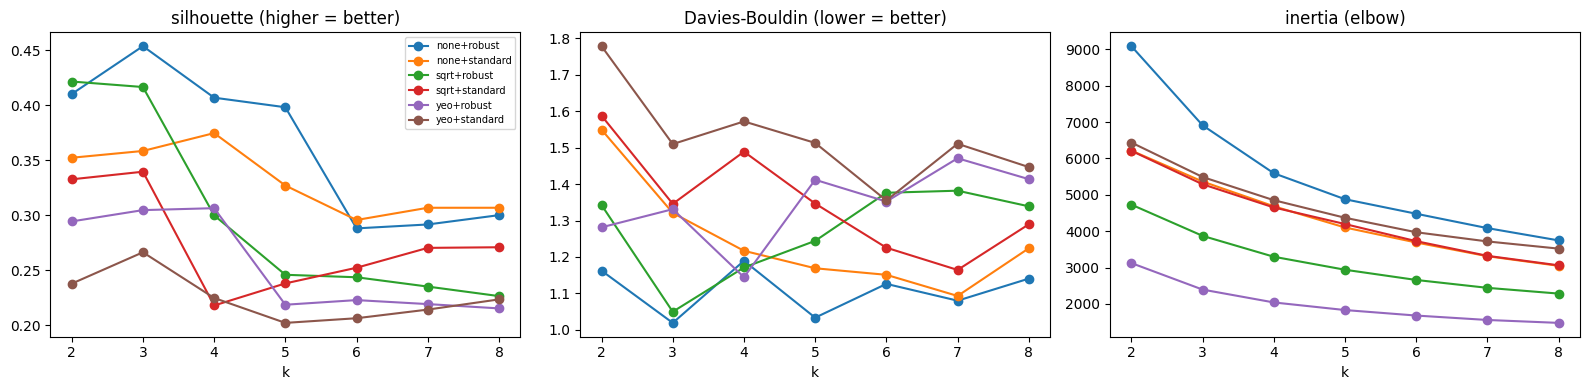

In [11]:
K_RANGE = range(2, 9)

rows = []
for (fs, vname), Xv in VARIANTS.items():
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xv)
        rows.append({
            'feature_set': fs, 'variant': vname, 'k': k,
            'silhouette': silhouette_score(Xv, km.labels_),
            'davies_bouldin': davies_bouldin_score(Xv, km.labels_),
            'inertia': km.inertia_,
            'smallest_cluster': np.bincount(km.labels_).min(),
        })
res_km = pd.DataFrame(rows)

# best k per variant (by silhouette) -- only comparable INSIDE the same variant
best = (res_km.sort_values('silhouette', ascending=False)
              .groupby(['feature_set', 'variant']).head(1)
              .sort_values(['feature_set', 'variant']))
print(best[['feature_set', 'variant', 'k', 'silhouette', 'davies_bouldin', 'smallest_cluster']].round(3).to_string(index=False))

# silhouette vs k, one line per variant (core set)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
core = res_km[res_km['feature_set'] == 'core']
for ax, col, title in zip(axes, ['silhouette', 'davies_bouldin', 'inertia'],
                          ['silhouette (higher = better)', 'Davies-Bouldin (lower = better)', 'inertia (elbow)']):
    for v, d in core.groupby('variant'):
        ax.plot(d['k'], d[col], marker='o', label=v)
    ax.set_title(title); ax.set_xlabel('k')
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [12]:
from sklearn.metrics import adjusted_rand_score as ARI

gt = pd.read_csv(ROOT / 'data' / 'ground_truth' / 'ground_truth_students.csv', encoding='utf-8-sig')
gt = gt.set_index('student_id').reindex(feat.index)          # EVALUATION ONLY, never a feature

core_variants = {v: X for (fs, v), X in VARIANTS.items() if fs == 'core'}
rng = np.random.default_rng(SEED)

def fit_labels(X, k):
    return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)

def stability(X, k, n_boot=30, frac=0.8):
    """Mean ARI between the full-data clustering and clusterings of 80% subsamples."""
    full = fit_labels(X, k)
    scores = []
    for _ in range(n_boot):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        sub = KMeans(n_clusters=k, n_init=5, random_state=int(rng.integers(1e6))).fit_predict(X.iloc[idx])
        scores.append(ARI(full[idx], sub))
    return np.mean(scores), np.std(scores)

rows, LABELS = [], {}
for v, X in core_variants.items():
    for k in (3, 4):
        lab = fit_labels(X, k); LABELS[(v, k)] = lab
        m, s = stability(X, k)
        rows.append({'variant': v, 'k': k,
                     'stability_ARI': m, 'stab_std': s,
                     'ARI_vs_archetype': ARI(gt['archetype'], lab),
                     'sizes': sorted(np.bincount(lab).tolist())})
cmp_df = pd.DataFrame(rows).sort_values(['k', 'stability_ARI'], ascending=[True, False])
print(cmp_df.round(3).to_string(index=False))

# do different variants find the same partition? (k=3 and k=4)
for k in (3, 4):
    names = list(core_variants)
    M = pd.DataFrame([[ARI(LABELS[(a, k)], LABELS[(b, k)]) for b in names] for a in names], index=names, columns=names)
    print(f"\nARI between variants, k={k}:"); print(M.round(2).to_string())

      variant  k  stability_ARI  stab_std  ARI_vs_archetype               sizes
  none+robust  3          0.986     0.063             0.046      [81, 142, 777]
   yeo+robust  3          0.982     0.009             0.496     [168, 199, 633]
  sqrt+robust  3          0.941     0.131             0.346      [27, 192, 781]
none+standard  3          0.879     0.179             0.311      [74, 205, 721]
sqrt+standard  3          0.819     0.274             0.301      [86, 200, 714]
 yeo+standard  3          0.807     0.260             0.285      [87, 255, 658]
   yeo+robust  4          0.983     0.008             0.503 [30, 139, 208, 623]
  sqrt+robust  4          0.976     0.010             0.521 [27, 157, 176, 640]
  none+robust  4          0.976     0.027             0.259 [79, 130, 153, 638]
sqrt+standard  4          0.907     0.202             0.173 [85, 185, 317, 413]
none+standard  4          0.831     0.177             0.286  [72, 74, 184, 670]
 yeo+standard  4          0.649     0.26

In [13]:
CHOSEN = [('yeo+robust', 3), ('yeo+robust', 4), ('sqrt+robust', 4)]
show_cols = FEATURE_SETS['core'] + ['std_pct'] + PROFILE_ONLY

for v, k in CHOSEN:
    lab = pd.Series(LABELS[(v, k)], index=feat.index, name='cluster')
    prof = feat[show_cols].groupby(lab).mean()
    prof.insert(0, 'size', lab.value_counts().sort_index())
    prof['at_risk_%'] = rules.at_risk(feat['att_rate'], feat['avg_pct']).groupby(lab).mean() * 100

    print(f"\n{'='*20} {v}  k={k} {'='*20}")
    print(prof.round(3).T.to_string())                      # clusters as columns
    print("\narchetype x cluster:")
    print(pd.crosstab(gt['archetype'], lab).to_string())
    print("\npay_profile x cluster:")
    print(pd.crosstab(gt['pay_profile'], lab).to_string())


==================== yeo+robust  k=3 ====================
cluster               0        1        2
size            633.000  199.000  168.000
att_rate          0.952    0.823    0.914
late_rate         0.020    0.021    0.021
avg_pct           0.889    0.600    0.785
pct_slope         0.003   -0.010    0.023
hw_avg            3.786    1.800    3.255
unpaid_rate       0.065    0.120    0.066
partial_rate      0.039    0.037    0.051
paid_late_rate    0.087    0.141    0.090
std_pct           0.071    0.117    0.103
exempt_rate       0.035    0.020    0.024
avg_delay_days    1.817    2.923    1.985
excused_rate      0.019    0.058    0.033
n_sessions       35.449   33.372   33.839
n_payments        8.858    8.372    8.464
at_risk_%         0.000   32.663    5.357

archetype x cluster:
cluster            0   1    2
archetype                    
at_risk            0  55    5
average          466  10   14
declining          0  25    0
dropout            0  23    7
gifted_absent     14   1 

In [14]:
def tail_rate(s, frac=1/3):
    n = max(int(len(s) * frac), 1)
    return s.iloc[-n:].mean()

# rec is already sorted by student_id, session_number
feat['att_recent'] = rec.groupby('student_id')['attended'].apply(tail_rate)
feat['att_change'] = feat['att_recent'] - feat['att_rate']      # negative = attendance fading

core = FEATURE_SETS['core']
SETS = {
    'core (baseline)':        core,
    'core - late_rate':       [c for c in core if c != 'late_rate'],
    'academic':               ['att_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'std_pct'],
    'academic + att_change':  ['att_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'std_pct', 'att_change'],
    'core - late + att_change': [c for c in core if c != 'late_rate'] + ['att_change'],
}

rows = []
for name, cols_ in SETS.items():
    X = prepare(cols_, 'yeo', 'robust')
    for k in (3, 4, 5):
        lab = fit_labels(X, k)
        m, s = stability(X, k, n_boot=20)
        rows.append({'features': name, 'k': k, 'stability': m, 'stab_std': s,
                     'ARI_vs_archetype': ARI(gt['archetype'], lab),
                     'dropout_in_one_cluster_%': pd.crosstab(gt['archetype'], lab).loc['dropout'].max() / 30 * 100,
                     'sizes': sorted(np.bincount(lab).tolist())})
abl = pd.DataFrame(rows)
print(abl.round(3).to_string(index=False))

                features  k  stability  stab_std  ARI_vs_archetype  dropout_in_one_cluster_%                    sizes
         core (baseline)  3      0.972     0.017             0.496                    76.667          [168, 199, 633]
         core (baseline)  4      0.987     0.009             0.503                    73.333      [30, 139, 208, 623]
         core (baseline)  5      0.909     0.176             0.312                    73.333 [30, 131, 203, 286, 350]
        core - late_rate  3      0.974     0.013             0.494                    76.667          [167, 201, 632]
        core - late_rate  4      0.982     0.009             0.509                    73.333      [30, 143, 207, 620]
        core - late_rate  5      0.988     0.013             0.355                    70.000 [31, 129, 170, 202, 468]
                academic  3      0.980     0.011             0.471                    70.000          [166, 202, 632]
                academic  4      0.956     0.110        

In [15]:
ACADEMIC = ['att_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'std_pct']
EXTRA    = ['unpaid_rate', 'paid_late_rate', 'excused_rate', 'n_sessions']
X_ac = prepare(ACADEMIC, 'yeo', 'robust')

def describe_clusters(lab):
    raw = feat[ACADEMIC + EXTRA].groupby(lab).mean()
    raw.insert(0, 'size', lab.value_counts().sort_index())

    # distance from the overall mean, in standard deviations (+ = above average, - = below)
    z = (feat[ACADEMIC + EXTRA].groupby(lab).mean() - feat[ACADEMIC + EXTRA].mean()) / feat[ACADEMIC + EXTRA].std()
    return raw, z

for k in (4, 5):
    lab = pd.Series(fit_labels(X_ac, k), index=feat.index, name='cluster')
    raw, z = describe_clusters(lab)

    print(f"\n==== academic  yeo+robust  k={k} ====")
    print("raw means:");          print(raw.round(3).T.to_string())
    print("\nvs overall (in SD):"); print(z.round(2).T.to_string())
    print("\narchetype x cluster (evaluation only):")
    print(pd.crosstab(gt['archetype'], lab).to_string())


==== academic  yeo+robust  k=4 ====
raw means:
cluster              0        1        2        3
size            31.000  624.000  206.000  139.000
att_rate         0.895    0.951    0.833    0.915
avg_pct          0.666    0.891    0.596    0.824
pct_slope       -0.052    0.003    0.001    0.025
hw_avg           2.285    3.801    1.824    3.476
std_pct          0.158    0.070    0.112    0.099
unpaid_rate      0.133    0.066    0.101    0.074
paid_late_rate   0.129    0.089    0.124    0.094
excused_rate     0.027    0.018    0.058    0.033
n_sessions      32.097   35.365   33.927   33.906

vs overall (in SD):
cluster            0     1     2     3
att_rate       -0.23  0.29 -0.82 -0.05
avg_pct        -1.03  0.54 -1.52  0.07
pct_slope      -3.88 -0.08 -0.19  1.49
hw_avg         -0.99  0.49 -1.44  0.17
std_pct         2.41 -0.51  0.89  0.43
unpaid_rate     0.32 -0.06  0.14 -0.01
paid_late_rate  0.15 -0.05  0.13 -0.02
excused_rate   -0.04 -0.24  0.66  0.10
n_sessions     -0.58  0.13 -0.

In [17]:
import plotly.express as px
import plotly.graph_objects as go

ACADEMIC = ['att_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'std_pct']
X_final = prepare(ACADEMIC, 'yeo', 'robust')

# same call as before (n_init=10, seed 42) so the result matches what we analyzed
feat['cluster'] = fit_labels(X_final, 5)

# --- name each cluster by its measured behaviour (ids can change between runs) ---
prof = feat.groupby('cluster')[ACADEMIC].mean()
names, rest = {}, list(prof.index)

c = prof['pct_slope'].idxmin();           names[c] = 'Sharply Declining'; rest.remove(c)
c = prof.loc[rest, 'pct_slope'].idxmax(); names[c] = 'Rising';            rest.remove(c)
c = prof.loc[rest, 'avg_pct'].idxmin();   names[c] = 'Struggling';        rest.remove(c)
c = prof.loc[rest, 'avg_pct'].idxmax();   names[c] = 'Top Performers';    rest.remove(c)
names[rest[0]] = 'Solid Regulars'

feat['segment'] = feat['cluster'].map(names)
order = ['Top Performers', 'Solid Regulars', 'Rising', 'Struggling', 'Sharply Declining']

# --- summary table: clustering features + profile-only columns ---
cols_show = ACADEMIC + ['excused_rate', 'unpaid_rate', 'paid_late_rate', 'n_sessions']
summary = feat.groupby('segment')[cols_show].mean()
summary.insert(0, 'size', feat['segment'].value_counts())
summary.insert(1, 'share_%', (summary['size'] / len(feat) * 100).round(1))
print(summary.loc[order].round(3).T.to_string())

# --- evaluation only: segments vs hidden archetypes ---
print("\nARI vs archetype:", round(ARI(gt['archetype'], feat['cluster']), 3))
print(pd.crosstab(gt['archetype'], feat['segment'])[order].to_string())

# --- Plotly 1: PCA scatter (hover shows the real, un-transformed values) ---
pca = PCA(n_components=2, random_state=SEED).fit(X_final)
P = pca.transform(X_final)
plot_df = pd.DataFrame({
    'PC1': P[:, 0], 'PC2': P[:, 1],
    'segment': feat['segment'].values,
    'student_id': feat.index,
    'att_rate': feat['att_rate'].round(3).values,
    'avg_pct': feat['avg_pct'].round(3).values,
    'pct_slope': feat['pct_slope'].round(3).values,
    'hw_avg': feat['hw_avg'].round(2).values,
})
fig = px.scatter(plot_df, x='PC1', y='PC2', color='segment',
                 category_orders={'segment': order},
                 hover_name='student_id',
                 hover_data={'PC1': False, 'PC2': False, 'att_rate': True,
                             'avg_pct': True, 'pct_slope': True, 'hw_avg': True},
                 opacity=0.7, title='KMeans k=5: students in PCA space')
fig.update_traces(marker=dict(size=6))
fig.update_xaxes(title=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
fig.update_yaxes(title=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
fig.update_layout(height=550, legend_title_text='')
fig.show()

# --- Plotly 2: how far each segment is from the overall mean (in SD) ---
z = ((feat.groupby('segment')[ACADEMIC].mean() - feat[ACADEMIC].mean()) / feat[ACADEMIC].std()).loc[order]
fig2 = px.imshow(z.round(2), text_auto=True, aspect='auto',
                 color_continuous_scale='RdBu', zmin=-4, zmax=4,
                 title='Segment profile vs overall mean (in SD)')
fig2.update_layout(height=400, coloraxis_colorbar_title='SD')
fig2.show()

segment         Top Performers  Solid Regulars   Rising  Struggling  Sharply Declining
size                   232.000         420.000  134.000     183.000             31.000
share_%                 23.200          42.000   13.400      18.300              3.100
att_rate                 0.961           0.943    0.913       0.824              0.895
avg_pct                  0.922           0.867    0.825       0.573              0.666
pct_slope                0.003           0.002    0.025       0.001             -0.052
hw_avg                   4.197           3.538    3.467       1.676              2.285
std_pct                  0.052           0.082    0.099       0.115              0.158
excused_rate             0.014           0.022    0.034       0.060              0.027
unpaid_rate              0.064           0.072    0.072       0.094              0.133
paid_late_rate           0.093           0.087    0.094       0.128              0.129
n_sessions              35.009          35.

## الشرايح النهائية لتقسيم الطلاب

استخدمنا خوارزمية `KMeans` مع `k=5` على الـ features الأكاديمية فقط، وهي `att_rate` و`avg_pct` و`pct_slope` و`hw_avg` و`std_pct` بعد التحويل والـ scaling المناسبين.

التحويل المستخدم هو `yeo-johnson` ثم `RobustScaler`، وثبّتنا `random_state=42` عشان النتيجة تتكرر بنفس الشكل.

أسماء الشرايح بتتحدد أوتوماتيك من خصائص كل كلاستر وليس من رقمه، ومبنية على اللي بنقيسه فعلاً من حضور وأداء واتجاه وواجب وثبات.

| الشريحة | الحجم | النسبة | الحضور | متوسط الدرجات | ميل الدرجات في الشهر | الواجب من خمسة | التذبذب |
|---|---|---|---|---|---|---|---|
| **Top Performers** | 232 | 23.2% | 96% | 92% | 0.003 | 4.2 | 0.052 |
| **Solid Regulars** | 420 | 42.0% | 94% | 87% | 0.002 | 3.5 | 0.082 |
| **Rising** | 134 | 13.4% | 91% | 83% | +0.025 | 3.5 | 0.099 |
| **Struggling** | 183 | 18.3% | 82% | 57% | 0.001 | 1.7 | 0.115 |
| **Sharply Declining** | 31 | 3.1% | 90% | 67% | -0.052 | 2.3 | 0.158 |

قيمة `ARI` مقابل الـ archetypes وصلت إلى `0.556`، وبنستخدمها للمقارنة فقط وليست جزءاً من التدريب. والأسماء بتدعمها الأرقام دي:

- شريحة `Sharply

In [18]:
from sklearn.neighbors import NearestNeighbors

X_ac = X_final
labels_km = feat['cluster'].values

def summarize(name, lab):
    lab = np.asarray(lab)
    mask = lab != -1                                    # -1 = noise (DBSCAN / HDBSCAN)
    n_cl = len(set(lab[mask]))
    sil = silhouette_score(X_ac[mask], lab[mask]) if n_cl > 1 else np.nan
    return {'method': name, 'clusters': n_cl, 'noise': int((~mask).sum()),
            'silhouette': sil,
            'ARI_vs_kmeans': ARI(labels_km, lab),
            'ARI_vs_archetype': ARI(gt['archetype'], lab),
            'sizes': sorted(np.bincount(lab[mask]).tolist(), reverse=True) if n_cl else []}

rows = [summarize('KMeans k=5', labels_km)]
rows.append(summarize('GMM k=5', GaussianMixture(5, covariance_type='full', n_init=5, random_state=SEED).fit_predict(X_ac)))
rows.append(summarize('Agglomerative (ward) k=5', AgglomerativeClustering(n_clusters=5, linkage='ward').fit_predict(X_ac)))

# DBSCAN: eps picked from the k-distance curve (min_samples = 2 * n_features)
ms = 2 * X_ac.shape[1]
kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X_ac).kneighbors(X_ac)[0][:, -1])

fig = go.Figure(go.Scatter(y=kd, mode='lines'))
fig.update_layout(title=f'k-distance curve (k={ms}): choose eps near the elbow',
                  xaxis_title='students (sorted)', yaxis_title='distance to k-th neighbour', height=380)
fig.show()

for q in (0.80, 0.90, 0.95):
    eps = float(np.quantile(kd, q))
    rows.append(summarize(f'DBSCAN eps={eps:.2f} (q{int(q*100)})', DBSCAN(eps=eps, min_samples=ms).fit_predict(X_ac)))

for mcs in (20, 50):
    rows.append(summarize(f'HDBSCAN min_cluster={mcs}', HDBSCAN(min_cluster_size=mcs, min_samples=10).fit_predict(X_ac)))

cmp_algo = pd.DataFrame(rows)
print(cmp_algo.round(3).to_string(index=False))

# Plotly: agreement with KMeans and with the archetypes
fig2 = go.Figure()
fig2.add_bar(x=cmp_algo['method'], y=cmp_algo['ARI_vs_kmeans'], name='ARI vs KMeans')
fig2.add_bar(x=cmp_algo['method'], y=cmp_algo['ARI_vs_archetype'], name='ARI vs archetype (evaluation only)')
fig2.update_layout(barmode='group', title='Agreement between algorithms', height=450, xaxis_tickangle=-30, yaxis_title='ARI')
fig2.show()

                  method  clusters  noise  silhouette  ARI_vs_kmeans  ARI_vs_archetype                    sizes
              KMeans k=5         5      0       0.323          1.000             0.556 [420, 232, 183, 134, 31]
                 GMM k=5         5      0       0.248          0.512             0.595 [443, 245, 153, 133, 26]
Agglomerative (ward) k=5         5      0       0.300          0.798             0.514 [405, 227, 203, 138, 27]
   DBSCAN eps=0.77 (q80)         2     63       0.570          0.080             0.103                [913, 24]
   DBSCAN eps=0.91 (q90)         2     33       0.560          0.062             0.075                [943, 24]
   DBSCAN eps=1.03 (q95)         2     14       0.555          0.052             0.059                [961, 25]
  HDBSCAN min_cluster=20         2     11       0.555          0.050             0.055                [963, 26]
  HDBSCAN min_cluster=50         2    330       0.447          0.259             0.304                [5

## مقارنة الخوارزميات

استخدمنا نفس الـ features ونفس التحويل مع كل الخوارزميات، عشان المقارنة تبقى عادلة.

| الخوارزمية | عدد الكلاسترات | الطلاب المرفوضين | التطابق مع KMeans | التطابق مع الأنماط الأصلية | الأحجام |
|---|---|---|---|---|---|
| `KMeans k=5` | 5 | 0 | 1.000 | 0.556 | 420 232 183 134 31 |
| `GMM k=5` | 5 | 0 | 0.512 | 0.595 | 443 245 153 133 26 |
| `Agglomerative ward k=5` | 5 | 0 | 0.798 | 0.514 | 405 227 203 138 27 |
| `DBSCAN eps=0.77` | 2 | 63 | 0.080 | 0.103 | 913 24 |
| `DBSCAN eps=0.91` | 2 | 33 | 0.062 | 0.075 | 943 24 |
| `DBSCAN eps=1.03` | 2 | 14 | 0.052 | 0.059 | 961 25 |
| `HDBSCAN min=20` | 2 | 11 | 0.050 | 0.055 | 963 26 |
| `HDBSCAN min=50` | 2 | 330 | 0.259 | 0.304 | 575 95 |

**الخوارزميات اللي بتحدد عدد الكلاسترات مسبقاً:**

- التلاتة لقوا نفس البنية العامة، خمس شرايح بأحجام متقاربة، وشريحة صغيرة حوالي `26` طالب.
- التطابق بين `Agglomerative` و`KMeans` عالي ووصل `0.798`، وده تأكيد إن التقسيم مش نتيجة افتراضات خوارزمية واحدة.
- أما `GMM` فتطابقه أقل مع `KMeans` وهو `0.512`، لكنه سجل `0.595` مع الأنماط الأصلية مقابل `0.556`. الفرق صغير، ومقياس الأنماط للتقييم فقط، ولم نقس ثبات `GMM` بنفس الطريقة اللي استخدمناها مع `KMeans`.

**الخوارزميات القائمة على الكثافة:**

- خوارزميتا `DBSCAN` و`HDBSCAN` طلّعوا كلاسترين فقط، واحد ضخم فيه حوالي `95%` من الطلاب وواحد صغير فيه حوالي `25` طالب.
- حجم الكلاستر الصغير قريب من عدد طلاب نمط `declining`، فغالباً هو نفس شريحة `Sharply Declining`.
- معنى كده إن باقي الطلاب سلسلة متصلة من غير فجوات كثافة، وشريحة المتراجعين هي الوحيدة المنفصلة بوضوح.
- قيمة `silhouette` العالية مضللة، لأنها محسوبة على كلاسترين فقط وبدون الطلاب المرفوضين.
- وفي `HDBSCAN` مع حجم أدنى `50` اتعتبر ثلث الطلاب تقريباً مرفوضين، فمش مفيد هنا.

**القرار:** نكمل مع `KMeans` و`k=5`، لأنه متطابق مع `Agglomerative` وأحجامه متوازنة وأسهل في الشرح والتسمية.

In [19]:
from scipy.stats import chi2_contingency, kruskal

order = ['Top Performers', 'Solid Regulars', 'Rising', 'Struggling', 'Sharply Declining']

stu = clean['Students'].set_index('student_id')[['grade', 'school_type', 'area', 'gender', 'status']]
prof_df = feat[['segment']].join(stu)

# --- 1) payment behaviour (not used for clustering) ---
PAY = ['unpaid_rate', 'partial_rate', 'paid_late_rate', 'exempt_rate', 'avg_delay_days']
pay_means = feat.groupby('segment')[PAY].mean().loc[order]
print(pay_means.round(3).to_string())

print("\nKruskal-Wallis (p-value, eta2 effect size):")
n = len(feat)
for c in PAY:
    groups = [g[c].dropna().values for _, g in feat.groupby('segment')]
    h, p = kruskal(*groups)
    eta2 = (h - len(groups) + 1) / (sum(len(g) for g in groups) - len(groups))
    print(f"  {c:15s} p = {p:.4f} | eta2 = {eta2:.3f}")

pm = pay_means[['unpaid_rate', 'partial_rate', 'paid_late_rate']].reset_index().melt(
    id_vars='segment', var_name='metric', value_name='rate')
fig = px.bar(pm, x='segment', y='rate', color='metric', barmode='group',
             category_orders={'segment': order},
             title='Payment behaviour by segment (not used in clustering)')
fig.update_layout(height=420, yaxis_tickformat='.0%', xaxis_title='', legend_title_text='')
fig.show()

# --- 2) student attributes (not used for clustering) ---
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

for c in ['grade', 'school_type', 'area', 'gender', 'status']:
    d = prof_df.dropna(subset=[c])
    ct = pd.crosstab(d['segment'], d[c]).loc[order]
    p = chi2_contingency(ct)[1]
    print(f"\n{c}: chi2 p = {p:.4f} | Cramer's V = {cramers_v(ct):.3f}   (% of each segment)")
    print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1).to_string())

                   unpaid_rate  partial_rate  paid_late_rate  exempt_rate  avg_delay_days
segment                                                                                  
Top Performers           0.064         0.048           0.093        0.030           2.023
Solid Regulars           0.072         0.031           0.087        0.036           1.725
Rising                   0.072         0.059           0.094        0.030           2.139
Struggling               0.094         0.027           0.128        0.016           2.514
Sharply Declining        0.133         0.100           0.129        0.032           4.008

Kruskal-Wallis (p-value, eta2 effect size):
  unpaid_rate     p = 0.0180 | eta2 = 0.008
  partial_rate    p = 0.0176 | eta2 = 0.008
  paid_late_rate  p = 0.1116 | eta2 = 0.004
  exempt_rate     p = 0.8016 | eta2 = -0.002
  avg_delay_days  p = 0.3486 | eta2 = 0.000



grade: chi2 p = 0.1384 | Cramer's V = 0.078   (% of each segment)
grade              أولى ثانوي  تالتة ثانوي  تانية ثانوي
segment                                                
Top Performers           29.7         37.9         32.3
Solid Regulars           32.1         33.8         34.0
Rising                   29.9         44.0         26.1
Struggling               39.9         31.7         28.4
Sharply Declining        29.0         29.0         41.9

school_type: chi2 p = 0.2971 | Cramer's V = 0.069   (% of each segment)
school_type        حكومي   خاص  لغات
segment                             
Top Performers      52.2  22.0  25.9
Solid Regulars      52.3  21.5  26.3
Rising              63.4  16.4  20.1
Struggling          59.6  18.0  22.4
Sharply Declining   41.9  25.8  32.3

area: chi2 p = 0.3013 | Cramer's V = 0.143   (% of each segment)
area               الأزاريطة  الإبراهيمية  السيوف  الشاطبي  العجمي  العصافرة  المنتزه  المندرة  الورديان  رشدي  سان ستيفانو  سموحة  سيدي بشر  س

## توصيف الشرايح بمتغيرات خارج التقسيم

الدفع وخصائص الطالب ما دخلوش في الكلاسترنج، فاستخدمناهم هنا للتوصيف بس. اعتمدنا على حجم الأثر لأن `p-value` مع `1000` طالب بتطلع معنوية لأي فرق صغير.

### الدفع

الفروق بين الشرايح في الدفع ضئيلة جداً، فقيم `eta2` كلها أقل من `0.01`. يعني الشريحة بتفسر أقل من واحد في المية من الاختلاف في سلوك الدفع.

| المقياس | p | eta2 |
|---|---|---|
| `unpaid_rate` | 0.018 | 0.008 |
| `partial_rate` | 0.018 | 0.008 |
| `paid_late_rate` | 0.112 | 0.004 |
| `exempt_rate` | 0.802 | -0.002 |
| `avg_delay_days` | 0.349 | 0.000 |

قيمتا `p` الأقل من `0.05` مش معنويتين فعلاً، لأننا عملنا `5` اختبارات، وبعد تصحيح `Bonferroni` الحد بيبقى `0.01`. و`eta2` السالبة معناها صفر تقريباً.

شريحة `Sharply Declining` أعلى شريحة في أغلب مقاييس الدفع، لكن عددها `31` طالب بس. فنعتبرها اتجاه وصفي ولا نبني عليها استنتاج.

### خصائص الطالب

| المتغير | Cramers V | p |
|---|---|---|
| `grade` | 0.078 | 0.138 |
| `school_type` | 0.069 | 0.297 |
| `gender` | 0.078 | 0.188 |
| `area` | 0.143 | 0.301 |
| `status` | 0.276 | 0.0000 |

- الصف والنوع والمدرسة ما بيفرّقوش بين الشرايح، فكل الأثر ضئيل وغير معنوي.
- المنطقة فيها `20` قيمة، وكتير من الخانات فيها صفر أو طالب واحد، فالقيمة `0.143` غير موثوقة ولا نفسرها جغرافياً.
- الاستثناء الوحيد هو `status`، فالمنسحبين `dropped` متركزين في شريحتين. في `Struggling` نسبتهم `10.9%` يعني حوالي `20` طالب، وفي `Sharply Declining` نسبتهم `16.1%` يعني `5` طلاب.
- باقي الشرايح نسبة الانسحاب فيها `3%` أو أقل، وده بيدعم إن الشرايح بتلقط خطر الانسحاب من غير ما نستخدمه في التقسيم.

**الخلاصة:** الشرايح بتعتمد على الأداء الأكاديمي بس، ومالهاش علاقة بالدفع ولا الديموغرافيا. والعلاقة الوحيدة المهمة هي مع الانسحاب، لكن حجمها متوسط ومش قوي.

## إجراءات مقترحة لكل شريحة

الإجراءات دي موجهة للمدرس، ومبنية على الأرقام اللي طلعت فوق. هي **مقترحات** لم نختبر تأثيرها على الطلاب، فاستخدمها كنقطة بداية وليست قواعد ثابتة.

### شريحة `Sharply Declining` المتراجعون بشدة

- **الأولوية:** الأولى، رغم إن عددهم `31` طالب بس.
- **الإشارة:** الدرجات بتنزل حوالي `5` نقط في الشهر وبشكل غير مستقر، لكن حضورهم لسه `90%`.
- **المقترح:** اتواصل مع الطالب وولي أمره بسرعة، واسأل عن سبب النزول قبل ما يبدأ يغيب.
- **ليه الآن:** نسبة الانسحاب فيهم `16%`، وهم لسه بيحضروا، يعني التدخل لسه ممكن.

### شريحة `Struggling` المتعثرون

- **الإشارة:** درجات `57%` وواجب `1.7` من خمسة وحضور `82%`، وعندهم غياب بعذر أكتر من غيرهم.
- **المقترح:** حصص تقوية أو متابعة أسبوعية للواجب، ومراجعة الأساسيات قبل الدروس الجديدة.
- **تنبيه:** حوالي `20` طالب منهم منسحبين، فابدأ بالطلاب اللي حضورهم واطي.
- **ملاحظة:** الشريحة واسعة وفيها أنماط مختلفة، فمش كل طالب فيها محتاج نفس الدعم.

### شريحة `Rising` الصاعدون

- **الإشارة:** الدرجات بتطلع حوالي `2.5` نقطة في الشهر، ومستواهم كويس (`83%`).
- **المقترح:** شجّعهم وقولهم إن تقدمهم ظاهر، عشان الاتجاه يستمر.
- **تنبيه:** راقب إن الاتجاه ما يقفش، لأنهم لسه أقل من المتفوقين.

### شريحة `Solid Regulars` المنتظمون

- **الإشارة:** درجات `87%` وواجب `3.5`، وكل حاجة فوق المتوسط بشكل خفيف وثابت.
- **المقترح:** متابعة عادية، وسؤال أو تحدي أصعب من وقت لتاني عشان يوصلوا لمستوى أعلى.

### شريحة `Top Performers` المتفوقون

- **الإشارة:** أعلى درجات (`92%`) وواجب (`4.2`) وأقل تذبذب.
- **المقترح:** مسائل تحدٍّ إضافية، أو إشراكهم في شرح الأفكار لزمايلهم.
- **تنبيه:** الفرق بينهم وبين المنتظمين في الدرجة مش في النوع، فالمعاملة قريبة جداً.

**ملاحظات على الاستخدام:**

- الدفع مش بيدخل في أي إجراء، لأن الفروق بين الشرايح فيه ضئيلة.
- الشريحة بتتحدد من الأداء الأكاديمي فقط، فمتستخدمهاش للحكم على ظروف الطالب.
- الطالب اللي درجاته في أقل من `3` شهور الشريحة بتاعته تقريبية.

In [20]:
# does the small density-based cluster match our "Sharply Declining" segment?
target = 'Sharply Declining'
is_target = (feat['segment'] == target).values
n_target = int(is_target.sum())

runs = {f'DBSCAN eps={q}': DBSCAN(eps=float(np.quantile(kd, p)), min_samples=ms).fit_predict(X_ac)
        for q, p in [('q80', 0.80), ('q90', 0.90), ('q95', 0.95)]}
runs['HDBSCAN min_cluster=20'] = HDBSCAN(min_cluster_size=20, min_samples=10).fit_predict(X_ac)

rows = []
for name, lab in runs.items():
    lab = np.asarray(lab)
    ids = [c for c in set(lab) if c != -1]
    small = min(ids, key=lambda c: (lab == c).sum())          # the smaller of the 2 clusters
    m = lab == small
    hit = int((m & is_target).sum())
    rows.append({'method': name,
                 'small_cluster_size': int(m.sum()),
                 f'of_which_{target}': hit,
                 'precision_%': round(hit / m.sum() * 100, 1),                 # how pure the cluster is
                 'recall_%': round(hit / n_target * 100, 1),                   # how many of the 31 it caught
                 'noise_that_are_target': int(((lab == -1) & is_target).sum())})
print(pd.DataFrame(rows).to_string(index=False))

# what are the members of the small cluster that are NOT Sharply Declining?
lab = np.asarray(runs['DBSCAN eps=q90'])
small = min([c for c in set(lab) if c != -1], key=lambda c: (lab == c).sum())
print("\nsegments inside the small DBSCAN cluster (q90):")
print(feat.loc[lab == small, 'segment'].value_counts().to_string())

                method  small_cluster_size  of_which_Sharply Declining  precision_%  recall_%  noise_that_are_target
        DBSCAN eps=q80                  24                          24        100.0      77.4                      6
        DBSCAN eps=q90                  24                          24        100.0      77.4                      4
        DBSCAN eps=q95                  25                          25        100.0      80.6                      3
HDBSCAN min_cluster=20                  26                          26        100.0      83.9                      1

segments inside the small DBSCAN cluster (q90):
segment
Sharply Declining    24


## هل شريحة Sharply Declining حقيقية؟

الخوارزميات القائمة على الكثافة طلّعت كلاستر صغير فيه حوالي `25` طالب. قارنّاه بالشريحة اللي سمّيناها `Sharply Declining` وعددها `31` طالب.

| الإعداد | حجم الكلاستر الصغير | منهم في الشريحة | الدقة | الاسترجاع |
|---|---|---|---|---|
| `DBSCAN eps=q80` | 24 | 24 | 100% | 77.4% |
| `DBSCAN eps=q90` | 24 | 24 | 100% | 77.4% |
| `DBSCAN eps=q95` | 25 | 25 | 100% | 80.6% |
| `HDBSCAN min=20` | 26 | 26 | 100% | 83.9% |

- كل الطلاب جوه الكلاستر الصغير من شريحة `Sharply Declining`، وما دخلوش طلاب من شرايح تانية في أي إعداد.
- الخوارزميات لقطت من `77%` لـ `84%` من طلاب الشريحة، والباقي اتصنّف `noise` أو فضل مع الكلاستر الكبير.
- الطلاب اللي ما اتلقطوش غالباً على حدود الشريحة، وميلهم أخف من الباقي.

**الخلاصة:** الكثافة فصلت نفس المجموعة من غير ما نحدد عدد الكلاسترات مسبقاً. وده تأكيد مستقل عن `KMeans` إن شريحة `Sharply Declining` مجموعة حقيقية، وإن باقي الطلاب سلسلة متصلة.

In [21]:
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, RobustScaler

ACADEMIC = ['att_rate', 'avg_pct', 'pct_slope', 'hw_avg', 'std_pct']

seg_pipe = Pipeline([
    ('yeo',    PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scale',  RobustScaler()),
    ('kmeans', KMeans(n_clusters=5, n_init=10, random_state=SEED)),
]).fit(feat[ACADEMIC])

# sanity check: the pipeline must reproduce the labels we already analyzed
labels_pipe = seg_pipe.predict(feat[ACADEMIC])
ari_check = ARI(feat['cluster'], labels_pipe)
print("ARI vs notebook labels:", round(ari_check, 4))
assert ari_check > 0.999

def name_segments(df, labels):
    """Name clusters from their measured behaviour (cluster ids change between runs)."""
    prof = df.groupby(labels)[['avg_pct', 'pct_slope']].mean()
    names, rest = {}, list(prof.index)
    c = prof['pct_slope'].idxmin();           names[c] = 'Sharply Declining'; rest.remove(c)
    c = prof.loc[rest, 'pct_slope'].idxmax(); names[c] = 'Rising';            rest.remove(c)
    c = prof.loc[rest, 'avg_pct'].idxmin();   names[c] = 'Struggling';        rest.remove(c)
    c = prof.loc[rest, 'avg_pct'].idxmax();   names[c] = 'Top Performers';    rest.remove(c)
    names[rest[0]] = 'Solid Regulars'
    return {int(k): v for k, v in names.items()}

cluster_to_segment = name_segments(feat, labels_pipe)
assert (pd.Series(labels_pipe, index=feat.index).map(cluster_to_segment) == feat['segment']).all()

# --- save the artifacts the Streamlit app will load ---
(ROOT / 'models').mkdir(exist_ok=True)
joblib.dump({'pipeline': seg_pipe, 'features': ACADEMIC,
             'cluster_to_segment': cluster_to_segment,
             'sklearn_version': sklearn.__version__},
            ROOT / 'models' / 'segmentation.joblib')

# students with grades in < 3 months have no real slope (it was set to 0): flag them
out = feat[ACADEMIC + ['n_sessions']].copy()
out['segment'] = feat['segment']
out['insufficient_data'] = feat.index.isin(nan_slope)

(ROOT / 'data' / 'segments').mkdir(parents=True, exist_ok=True)
out.reset_index().to_csv(ROOT / 'data' / 'segments' / 'student_segments.csv', index=False, encoding='utf-8-sig')

# reload check: the saved file must give the same segments as the live pipeline
bundle = joblib.load(ROOT / 'models' / 'segmentation.joblib')
reloaded = pd.Series(bundle['pipeline'].predict(feat[bundle['features']]), index=feat.index).map(bundle['cluster_to_segment'])
assert (reloaded == feat['segment']).all()

print("sklearn version:", sklearn.__version__)
print(out['segment'].value_counts().to_string())
print("insufficient data:", int(out['insufficient_data'].sum()), "students")

ARI vs notebook labels: 1.0
sklearn version: 1.7.2
segment
Solid Regulars       420
Top Performers       232
Struggling           183
Rising               134
Sharply Declining     31
insufficient data: 3 students
